# 16 GRB 211211A: systematics, pile-up and the low-energy break in two detectors

Notebook 14 ran the pipeline on GRB 211211A but left three things open, which this notebook closes. They are all on the spectral
side and use nothing new except the checks themselves.

1. The systematic errors: the same three analysis choices as for GRB 230307A (notebook 12, section 11)
2. Pile-up: the rates and the simulation from notebook 15 (a check), since this burst is bright too
3. The low-energy break, fitted with n2 and with na separately. For GRB 230307A only na sees below 40 keV, so GBM alone couldn't tell a
   break from na's calibration. Here two NaI detectors both see the low energies, so the test can be done

The results go in a new file, `shared/epeak_211211A_systematics.csv`. `shared/epeak_211211A.csv` stays as notebook 14 wrote it.

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import minimize

from gdt.core.spectra.functions import Band, Comptonized
from gdt.missions.fermi.gbm.response import GbmRsp2
from gdt.missions.fermi.gbm.tte import GbmTte

import settings_211211A as S
from lightcurve_tools import aligned_bin_edges, tte_path
from spectral_fit_tools import (make_spectra, window_response, rsp2_path, channel_mask, fit_model, scaled_starts, cstat, covariance,
                                BandLowBreak)
from pileup_tools import record, channel_sampler

warnings.filterwarnings("ignore")     # GDT's fitter warns on most trial steps near the parameter limits
pd.set_option("display.width", 200)

SHARED = S.WINDOWS_FILE.parent
windows = pd.read_csv(S.WINDOWS_FILE, comment="#", index_col="label")
table = pd.read_csv(SHARED / "epeak_211211A.csv").set_index("label")
WIN = {label: (row.t_start, row.t_stop) for label, row in windows.iterrows()}
DETECTORS = S.SPECTRAL_DETECTORS

spectra = {d: make_spectra(S.DATA_DIR, S.BURST_ID, d, WIN, S.BKG_WINDOWS, S.BKG_ORDER)[0] for d in DETECTORS}
responses = {(d, label): window_response(S.DATA_DIR, S.BURST_ID, d, WIN[label])[0] for d in DETECTORS for label in WIN}

def window_data(label, dets=DETECTORS, ranges=(S.FIT_RANGE_NAI, S.FIT_RANGE_BGO), rsp_override=None, bkg_override=None):
    phas = [spectra[d][label][0] for d in dets]
    baks = [(bkg_override or {}).get(d, spectra[d][label][1]) for d in dets]
    rsps = [(rsp_override or {}).get(d, responses[d, label]) for d in dets]
    masks = [channel_mask(r, ranges[1] if d.startswith("b") else ranges[0]) for r, d in zip(rsps, dets)]
    return phas, baks, rsps, masks

print(len(WIN), "windows;", table.model.value_counts().to_dict())

23 windows; {'BandLowBreak': 14, 'Band': 7, 'Comptonized': 2}


## 1. The base fits

First the fit notebook 14 chose for each window, starting from its table. If I get the same C-stat and E_peak back, the rest can start from
these fits and doesn't need the whole grid of starting points again. Notebook 14's rule for choosing the model stays as it is.

In [2]:
def start_vector(label):
    row = table.loc[label]
    if row.model == "BandLowBreak":
        found = re.search(r"break at ([\d.]+) keV, alpha1 (-?[\d.]+) below it, alpha2 (-?[\d.]+) above", row.notes)
        eb, a1, a2 = (float(x) for x in found.groups())
        return BandLowBreak(), [1.0, eb, a1, a2, row.Epeak_keV, min(row.beta, -2.05), 2.0, 100.0]
    if row.model == "Band":
        return Band(), [1.0, row.Epeak_keV, row.alpha, row.beta, 100.0]
    return Comptonized(), [1.0, row.Epeak_keV, row.alpha, 100.0]

EPEAK_INDEX = {"BandLowBreak": 4, "Band": 1, "Comptonized": 1}

def fit_again(label, data, start):
    function, _ = start_vector(label)
    k = EPEAK_INDEX[table.model[label]]
    # also from E_peak moved either way, so that a small change in the data can't leave the fit sitting where it started
    shapes = [list(start)] + [[v * f if i == k else v for i, v in enumerate(start)] for f in (0.8, 1.25)]
    if table.model[label] == "Band":
        shapes += [[1.0, e, a, b, 100.0] for e in (30.0, 60.0, 100.0) for a in (-0.8, -1.2) for b in (-2.1, -2.3, -3.0)]
    elif table.model[label] == "Comptonized":
        shapes += [[1.0, e, a, 100.0] for e in (50.0, 100.0, 300.0) for a in (-0.6, -1.2)]
    fit = fit_model(*data, function, scaled_starts(function, *data, shapes) + [start], polish=True)
    return function, fit

base = {}
rows = []
for label in WIN:
    data = window_data(label)
    _, start = start_vector(label)
    function, fit = fit_again(label, data, start)
    k = EPEAK_INDEX[table.model[label]]
    base[label] = list(function.default_values)
    rows.append(dict(label=label, model=table.model[label], Epeak_table=table.Epeak_keV[label], Epeak_again=fit.parameters[k],
                     C_table=table.cstat[label], C_again=cstat(fit)))
check = pd.DataFrame(rows).set_index("label")
check["dC"] = check.C_again - check.C_table
check["Epeak_ratio"] = check.Epeak_again / check.Epeak_table
print("largest |dC|:", round(check.dC.abs().max(), 3), "| largest E_peak difference:", round((check.Epeak_ratio - 1).abs().max() * 100, 3), "%")
check.round(3)

largest |dC|: 0.141 | largest E_peak difference: 17.711 %


,model,Epeak_table,Epeak_again,C_table,C_again,dC,Epeak_ratio
label,,,,,,,
pre,Comptonized,66.748,66.748,390.333,390.333,0.000,1.000
g00_02,BandLowBreak,1565.830,1565.548,328.269,328.269,0.000,1.000
g02_04,BandLowBreak,1212.140,1212.141,585.031,585.034,0.003,1.000
g04_06,BandLowBreak,828.512,828.508,495.844,495.844,0.000,1.000
g06_08,BandLowBreak,1606.910,1606.910,691.679,691.680,0.001,1.000
g08_10,BandLowBreak,1257.740,1257.740,463.660,463.660,0.000,1.000
g10_12,BandLowBreak,532.934,532.934,439.170,439.170,0.000,1.000
g12_16,Comptonized,203.350,203.479,527.968,527.967,-0.001,1.001
g16_18,BandLowBreak,370.705,370.705,469.744,469.744,0.000,1.000


The base fits come back. C agrees within 0.01 in all windows but one and E_peak within 0.2%. The exception is `f2_27_66`, which comes back at 47.2 keV instead of 57.3 keV with C lower by 0.14. So the two-break E_peak in that window is very flat, as its statistical error of 15.7 keV already says. I leave notebook 14's table as it is, and the checks below start from these refits.

## 2. Systematic errors

The same three choices as notebook 12, each changed on its own in every window: the BGO lower edge (300 instead of 200 keV: 250 keV would change nothing here, since it falls inside the first channel kept, 217-251 keV), the response
(interpolated to the window centre instead of the DRM covering it), and the background polynomial (order 2 instead of 3). The systematic error is the
three shifts in quadrature. Each fit starts from the base fit of that window and stays with that window's model.

In [3]:
bkg_order2 = {}
for det in DETECTORS:
    sp2 = make_spectra(S.DATA_DIR, S.BURST_ID, det, WIN, S.BKG_WINDOWS, 2)[0]
    for label in WIN:
        bkg_order2.setdefault(label, {})[det] = sp2[label][1]

rows = []
for label, (t0, t1) in WIN.items():
    interp = {d: GbmRsp2.open(rsp2_path(S.DATA_DIR, S.BURST_ID, d)).interpolate(0.5 * (t0 + t1)) for d in DETECTORS}
    variants = {"BGO from 300 keV": window_data(label, ranges=(S.FIT_RANGE_NAI, (300.0, 40000.0))),
                "interpolated response": window_data(label, rsp_override=interp),
                "background order 2": window_data(label, bkg_override=bkg_order2[label])}
    k = EPEAK_INDEX[table.model[label]]
    row = dict(label=label, model=table.model[label], Epeak=check.Epeak_again[label], alpha=base[label][2])
    for name, data in variants.items():
        function, fit = fit_again(label, data, base[label])
        row[f"dEpeak {name}"] = fit.parameters[k] - check.Epeak_again[label]
        row[f"dalpha {name}"] = fit.parameters[2] - base[label][2]
    rows.append(row)
syst = pd.DataFrame(rows).set_index("label")
syst["Epeak_sys"] = np.sqrt((syst.filter(like="dEpeak")**2).sum(axis=1))
syst["alpha_sys"] = np.sqrt((syst.filter(like="dalpha")**2).sum(axis=1))
syst["Epeak_stat"] = 0.5 * (table.Epeak_err_lo + table.Epeak_err_hi)
syst["sys_over_stat"] = syst.Epeak_sys / syst.Epeak_stat
syst["sys_over_Epeak"] = syst.Epeak_sys / syst.Epeak
syst[["model", "Epeak", "Epeak_stat", "Epeak_sys", "sys_over_stat", "sys_over_Epeak", "dEpeak BGO from 300 keV", "dEpeak interpolated response",
      "dEpeak background order 2", "alpha_sys"]].round(3)

,model,Epeak,Epeak_stat,Epeak_sys,sys_over_stat,sys_over_Epeak,dEpeak BGO from 300 keV,dEpeak interpolated response,dEpeak background order 2,alpha_sys
label,,,,,,,,,,
pre,Comptonized,66.748,5.940,1.068,0.180,0.016,0.140,0.000,-1.059,0.036
g00_02,BandLowBreak,1565.548,271.404,55.937,0.206,0.036,8.685,2.837,55.186,0.172
g02_04,BandLowBreak,1212.141,55.915,28.449,0.509,0.023,25.566,1.237,12.418,0.031
g04_06,BandLowBreak,828.508,55.962,22.802,0.407,0.028,20.796,4.827,8.011,0.034
g06_08,BandLowBreak,1606.910,37.136,13.245,0.357,0.008,7.852,7.520,7.565,0.018
g08_10,BandLowBreak,1257.740,59.438,14.994,0.252,0.012,2.467,7.454,12.774,0.066
g10_12,BandLowBreak,532.934,80.797,12.673,0.157,0.024,-4.842,10.431,5.325,0.083
g12_16,Comptonized,203.479,17.321,4.268,0.246,0.021,-3.710,1.660,-1.302,0.023
g16_18,BandLowBreak,370.705,47.702,21.299,0.446,0.057,-15.862,7.259,-12.221,0.105


The systematic error is 0.45-56 keV, and in every window it is smaller than the statistical error: the median ratio is 0.30 and the largest is 0.78, in `f2_01_10`. As a share of E_peak the median is 2.4%. The two largest are `g34_38` (20%, the BGO edge, in a window where E_peak is 108 +/- 48 keV anyway) and `g50_60` (9%, the background order, in a faint window).

Which choice matters depends on the window. Where the two-break E_peak is high in the first 10 s, it is set by the BGO, so the BGO edge moves it by up to 26 keV, and in the faintest of them (`g00_02`, mostly background) the background order moves it by 55 keV out of a statistical error of 271 keV. The response moves it by at most about 10 keV. After 26 s, with E_peak at 40-65 keV (apart from `g34_38`), all three are small, at most 3.4 keV, and the largest shifts are from the background order in the faintest windows, which is what I'd expect.

So for this burst the fit errors are still the larger part. These aren't the only uncertainty: the ~10% difference between instruments in notebook 15 was measured on GRB 230307A and I can't measure it here.

## 3. Pile-up

Recorded rates per detector in each window, and the simulation from notebook 15 (a check, not a result) in the windows where b0 passes 20 kcps, which is where
the rule of thumb from notebook 15 starts to give ~1%. The simulation needs a Band shape, so it gives the effect on Band's E_peak in those windows, which is
only a guide to the two-break E_peak the table uses.

In [4]:
events = {}
for det in DETECTORS:
    tte = GbmTte.open(tte_path(S.DATA_DIR, S.BURST_ID, det))
    events[det] = np.sort(np.asarray(tte.data.times))
    tte.close()
edges = aligned_bin_edges((-2.0, 80.0), 0.016)
centres = 0.5 * (edges[:-1] + edges[1:])
rates = pd.DataFrame({det: np.histogram(events[det], bins=edges)[0] / np.diff(edges) / 1e3 for det in DETECTORS}, index=centres)

def inside(index, interval):
    return (index > interval[0]) & (index < interval[1])

rate_rows = []
for label, window in WIN.items():
    local = rates[inside(rates.index, window)]
    rate_rows.append(dict(label=label, **{f"{d}_max_kcps": local[d].max() for d in DETECTORS}, **{f"{d}_median_kcps": local[d].median() for d in DETECTORS}))
rate_table = pd.DataFrame(rate_rows).set_index("label")
rate_table.round(1)

,n2_max_kcps,na_max_kcps,b0_max_kcps,n2_median_kcps,na_median_kcps,b0_median_kcps
label,,,,,,
pre,7.7,6.8,3.1,2.0,1.9,1.9
g00_02,37.6,26.6,34.5,1.9,1.9,2.0
g02_04,43.5,31.8,36.1,15.4,11.4,7.3
g04_06,32.6,24.7,22.7,13.1,9.9,5.6
g06_08,50.9,40.0,42.4,28.8,22.1,18.1
g08_10,30.9,26.2,24.6,10.2,7.7,4.4
g10_12,12.8,10.5,5.6,7.4,5.4,3.2
g12_16,5.6,7.2,3.4,3.3,2.8,2.2
g16_18,11.9,10.3,6.5,6.1,4.6,2.9


In [5]:
TAU, TAU_OVERFLOW = 2.6, 10.0      # us
band = Band()

def channel_edges(rsp):
    return np.asarray(rsp.ebounds.low_edges()), np.asarray(rsp.ebounds.high_edges())

def simulate_counts(rsp, background_rate, theta, recorded_rates, durations, num_detections, rng):
    lo, hi = channel_edges(rsp)
    folded = np.asarray(rsp.drm.fold_spectrum(Band().eval, theta))
    overflow_share = folded[-1] / folded.sum()
    tau = TAU * (1 - overflow_share) + TAU_OVERFLOW * overflow_share
    piled, clean, exposure = 0.0, 0.0, 0.0
    for rate, duration in zip(recorded_rates, durations):
        # never below the background: grouping by b0's rate picks bins that fluctuate low, and in a mostly quiet window that would leave the b0 simulation short of counts
        detection_rate = max(rate / (1 - rate * tau), background_rate.sum())
        amplitude = max(detection_rate - background_rate.sum(), 0.0) / folded.sum()
        spectrum = amplitude * folded + background_rate
        heights, total = record(channel_sampler(spectrum, lo, hi, rng), detection_rate, lo[0], lo[-1], num_detections, rng)
        over = (heights >= lo[-1]).sum()
        live = total - (len(heights) - over) * TAU - over * TAU_OVERFLOW
        piled = piled + np.histogram(heights, bins=np.append(lo, np.inf))[0] * duration / total
        clean = clean + spectrum * duration * live / total
        exposure += duration * live / total
    return piled, clean, exposure

def band_cstat(x, counts, exposure, geometry, masks):
    amplitude, e_peak, alpha, beta = np.exp(x[0]), np.exp(x[1]), x[2], x[3]
    if beta >= -2.001 or alpha <= beta:
        return 1e12
    total = 0.0
    for det in DETECTORS:
        energy, width, matrix, background_rate = geometry[det]
        model = (band.eval([amplitude, e_peak, alpha, beta, 100.0], energy) * width) @ matrix + background_rate
        mu = np.maximum(model * exposure[det], 1e-9)[masks[det]]
        n = counts[det][masks[det]]
        term = mu - n
        term[n > 0] += n[n > 0] * np.log(n[n > 0] / mu[n > 0])
        total += 2 * term.sum()
    return total

def refit(counts, exposure, geometry, masks, shape):
    energy, width, matrix, background_rate = geometry[DETECTORS[0]]
    unit = (band.eval([1.0, shape[0], shape[1], shape[2], 100.0], energy) * width) @ matrix
    amplitude = (counts[DETECTORS[0]].sum() / exposure[DETECTORS[0]] - background_rate.sum()) / unit.sum()
    x = [np.log(amplitude), np.log(shape[0]), shape[1], shape[2]]
    for _ in range(2):
        x = minimize(band_cstat, x, args=(counts, exposure, geometry, masks), method="Nelder-Mead",
                     options=dict(maxiter=4000, xatol=1e-4, fatol=1e-3)).x
    return np.exp(x[1]), x[2]

rng = np.random.default_rng(16)
BAND_GRID = [[1.0, e, a, b, 100.0] for e in (100.0, 300.0, 900.0) for a in (-0.6, -1.2) for b in (-2.6, -4.0, -6.0)]

def pileup_bias(label, num_detections=500000, groups=4):
    data = window_data(label)
    function = Band()
    fit = fit_model(*data, function, scaled_starts(function, *data, BAND_GRID), polish=True)
    A, ep, al, be = fit.parameters
    be = min(be, -2.05)
    geometry, masks = {}, {}
    for det, rsp, bak in zip(DETECTORS, data[2], data[1]):
        low, high = np.asarray(rsp.drm.photon_bins.low_edges()), np.asarray(rsp.drm.photon_bins.high_edges())
        background_rate = np.asarray(bak.rates) / 1e6
        geometry[det] = (np.sqrt(low * high), high - low, np.asarray(rsp.drm.matrix), background_rate)
        masks[det] = channel_mask(rsp, S.FIT_RANGE_BGO if det.startswith("b") else S.FIT_RANGE_NAI)
    local = rates[inside(rates.index, WIN[label])]
    order = np.array_split(np.argsort(local["b0"].values), groups)
    piled, clean, exposure = {}, {}, {}
    theta = [1.0, ep, al, be, 100.0]
    for det, rsp in zip(DETECTORS, data[2]):
        levels = [local[det].values[g].mean() / 1e3 for g in order]
        durations = [len(g) * 0.016e6 for g in order]
        piled[det], clean[det], exposure[det] = simulate_counts(rsp, geometry[det][3], theta, levels, durations, num_detections, rng)
    e0, a0 = refit(clean, exposure, geometry, masks, (ep, al, be))
    e1, a1 = refit(piled, exposure, geometry, masks, (ep, al, be))
    return dict(label=label, Epeak_band=ep, beta_band=be, Epeak_ratio=e1 / e0, dalpha=a1 - a0)

busy = [label for label in WIN if rate_table.b0_max_kcps[label] > 20.0]
print("windows simulated:", busy)
pileup = pd.DataFrame([pileup_bias(label) for label in busy]).set_index("label")
pileup.round(3)

windows simulated: ['g00_02', 'g02_04', 'g04_06', 'g06_08', 'g08_10', 'f2_01_10']


,Epeak_band,beta_band,Epeak_ratio,dalpha
label,,,,
g00_02,943.090,-2.513,1.017,-0.004
g02_04,683.026,-2.422,1.002,0.006
g04_06,460.566,-2.341,0.998,0.005
g06_08,810.600,-2.345,1.007,0.008
g08_10,579.969,-2.357,1.001,0.002
f2_01_10,696.386,-2.348,1.008,0.003


The rates stay under where Chaplin et al. say pile-up matters (60-70 kcps recorded). In 16 ms bins n2 reaches 51 kcps and b0 42 kcps, both in `g06_08`, with medians over that window of 29 and 18 kcps. The simulation moves Band's E_peak by 0.1-0.8% in five of the six windows, and by 1.7% in `g00_02`, where E_peak is only known to 15% and different seeds give 0-1.7%. alpha moves by less than 0.01. GRB 211211A has no data gaps either (notebook 17). So pile-up isn't a concern for this burst.

`g00_02` first came out at 0.86 here, the same with three seeds and from every starting point, and that was the simulation, not pile-up. The rate is set in four groups of bins sorted by b0's rate, and in a window that's mostly background the lowest group is picked to sit below the background. The simulated b0 was then 3.4% short of counts, which is what moved the fit. Now the rate is never below the background. Notebook 15 doesn't have that floor, but its ratios don't show the problem (0.996-1.003 in the faintest windows), because those windows sit further above the background.

## 4. The low-energy break with n2 and with na

For GRB 230307A this test was impossible (notebook 08). Here it isn't, if both detectors really do see the low energies. So first the viewing angles, the
effective areas and the net counts below 40 keV, then the fits: Band and the two-break model in every slice where notebook 14 chose the two-break model, with n2 + b0 and
with na + b0. If the break came from a calibration problem in one detector, it would be there in one fit and not the other, or at a different energy.

In [6]:
def area_at(rsp, energy):
    low, high = np.asarray(rsp.drm.photon_bins.low_edges()), np.asarray(rsp.drm.photon_bins.high_edges())
    i = np.searchsorted(high, energy)
    return np.asarray(rsp.drm.matrix)[i].sum() if (i < len(low) and low[i] <= energy) else np.nan

TWO_BREAK = [label for label in table.index if table.model[label] == "BandLowBreak" and label.startswith("g")]
reference = "g06_08"
rows = []
for det in ("n2", "na"):
    with fits.open(rsp2_path(S.DATA_DIR, S.BURST_ID, det)) as h:
        trigger = h[0].header["TRIGTIME"]
        angle = [e.header["DET_ANG"] for e in h[2:] if e.header["TSTOP"] - trigger > -1.0][0]
    rsp = responses[det, reference]
    lo, hi = channel_edges(rsp)
    low_energy = (lo >= 8.0) & (hi <= 40.0)
    net = {}
    for label in TWO_BREAK:
        pha, bkg = spectra[det][label]
        net[label] = (np.asarray(pha.data.counts, float) - np.asarray(bkg.counts))[low_energy].sum()
    rows.append(dict(detector=det, angle_deg=angle, area_25keV_cm2=area_at(rsp, 25.0), area_100keV_cm2=area_at(rsp, 100.0), net_8_40keV_all_slices=sum(net.values())))
pd.DataFrame(rows).set_index("detector").round(1)

,angle_deg,area_25keV_cm2,area_100keV_cm2,net_8_40keV_all_slices
detector,,,,
n2,30.1,96.5,123.1,86591.2
na,49.5,67.0,95.3,55919.0


In [7]:
def lowbreak_shapes(epeak):
    return [[1.0, eb, a1, a2, ep, b, 2.0, 100.0] for eb in (20.0, 50.0, 100.0) for a1 in (-0.4, -0.7)
            for a2 in (-1.2, -1.5) for ep in (epeak, 2 * epeak) for b in (-2.5, -3.5)]

def cov_errors(fit):
    try:
        with np.errstate(invalid="ignore"):
            return np.sqrt(np.diag(covariance(fit)))
    except np.linalg.LinAlgError:
        return np.full(len(fit.parameters), np.nan)

rows = []
for label in TWO_BREAK:
    for pair in (["n2", "b0"], ["na", "b0"]):
        data = window_data(label, dets=pair)
        function = Band()
        band_fit = fit_model(*data, function, scaled_starts(function, *data, BAND_GRID), polish=True)
        A, ep, al, be = band_fit.parameters
        lb = BandLowBreak()
        starts = scaled_starts(lb, *data, lowbreak_shapes(table.Epeak_keV[label]))[:12] + scaled_starts(lb, *data, [base[label]]) + [[A, 2.0, al, al, ep, min(be, -2.05), 2.0, 100.0]]
        lb_fit = fit_model(*data, lb, starts, polish=True)
        err = cov_errors(lb_fit)
        eb, a1, a2, epk, b = lb_fit.parameters[1:6]
        rows.append(dict(label=label, detector=pair[0], Eb=eb, Eb_err=err[1], alpha1=a1, alpha1_err=err[2], alpha2=a2, alpha2_err=err[3], Epeak=epk, Epeak_err=err[4], beta=b,
                         dC_band_minus_lowbreak=cstat(band_fit) - cstat(lb_fit), C_per_dof=cstat(lb_fit) / lb_fit.dof,
                         clean=bool(S.FIT_RANGE_NAI[0] < eb < 0.5 * epk and lb.min_values[2] + 1e-3 < a1 < lb.max_values[2] - 1e-3 and b < -2.01)))
pairs = pd.DataFrame(rows)
wide = pairs.pivot(index="label", columns="detector").reindex(TWO_BREAK)
compare = pd.DataFrame({"dC_n2": wide["dC_band_minus_lowbreak"]["n2"], "dC_na": wide["dC_band_minus_lowbreak"]["na"],
                        "Eb_n2": wide["Eb"]["n2"], "Eb_n2_err": wide["Eb_err"]["n2"], "Eb_na": wide["Eb"]["na"], "Eb_na_err": wide["Eb_err"]["na"],
                        "a1_n2": wide["alpha1"]["n2"], "a1_n2_err": wide["alpha1_err"]["n2"], "a1_na": wide["alpha1"]["na"], "a1_na_err": wide["alpha1_err"]["na"],
                        "a2_n2": wide["alpha2"]["n2"], "a2_na": wide["alpha2"]["na"], "clean_n2": wide["clean"]["n2"], "clean_na": wide["clean"]["na"]})
compare["Eb_sigma"] = (compare.Eb_n2 - compare.Eb_na) / np.hypot(compare.Eb_n2_err, compare.Eb_na_err)
compare["a1_sigma"] = (compare.a1_n2 - compare.a1_na) / np.hypot(compare.a1_n2_err, compare.a1_na_err)
for det, g in pairs[pairs.clean].groupby("detector"):
    print(f"{det}: E_b {g.Eb.max():.1f} down to {g.Eb.min():.1f} keV; mean alpha1 {g.alpha1.mean():.2f} (scatter {g.alpha1.std():.2f}), mean alpha2 {g.alpha2.mean():.2f} (scatter {g.alpha2.std():.2f}), from {len(g)} slices")
compare.astype({"clean_n2": bool, "clean_na": bool}).round(2)

n2: E_b 66.4 down to 16.2 keV; mean alpha1 -0.25 (scatter 0.34), mean alpha2 -1.57 (scatter 0.18), from 12 slices
na: E_b 90.1 down to 12.0 keV; mean alpha1 -0.28 (scatter 0.47), mean alpha2 -1.57 (scatter 0.19), from 11 slices


,dC_n2,dC_na,Eb_n2,Eb_n2_err,Eb_na,Eb_na_err,a1_n2,a1_n2_err,a1_na,a1_na_err,a2_n2,a2_na,clean_n2,clean_na,Eb_sigma,a1_sigma
label,,,,,,,,,,,,,,,,
g00_02,11.95,7.57,31.30,17.88,7.65,NaN,-0.88,0.24,2.00,NaN,-1.40,-1.35,True,False,NaN,NaN
g02_04,193.98,94.74,66.39,11.64,90.14,27.18,-0.63,0.06,-0.76,0.07,-1.36,-1.36,True,True,-0.80,1.39
g04_06,134.23,91.44,35.43,6.57,36.73,8.55,-0.53,0.11,-0.53,0.15,-1.38,-1.38,True,True,-0.12,-0.02
g06_08,902.35,519.57,51.63,4.68,54.21,6.57,-0.34,0.06,-0.43,0.07,-1.31,-1.27,True,True,-0.32,1.07
g08_10,269.29,156.73,26.13,4.25,25.46,5.41,-0.15,0.20,-0.15,0.28,-1.44,-1.42,True,True,0.10,0.02
g10_12,62.15,56.39,26.11,4.32,24.48,6.08,-0.09,0.25,-0.01,0.43,-1.82,-1.76,True,True,0.22,-0.16
g16_18,35.53,33.57,28.71,7.75,12.00,7.05,-0.55,0.22,0.95,2.07,-1.68,-1.57,True,True,1.60,-0.72
g18_20,105.40,59.82,22.76,4.60,23.40,6.67,-0.02,0.31,-0.38,0.35,-1.65,-1.58,True,True,-0.08,0.77
g20_22,55.69,48.79,22.06,6.75,20.73,6.82,-0.24,0.36,-0.07,0.55,-1.61,-1.67,True,True,0.14,-0.27


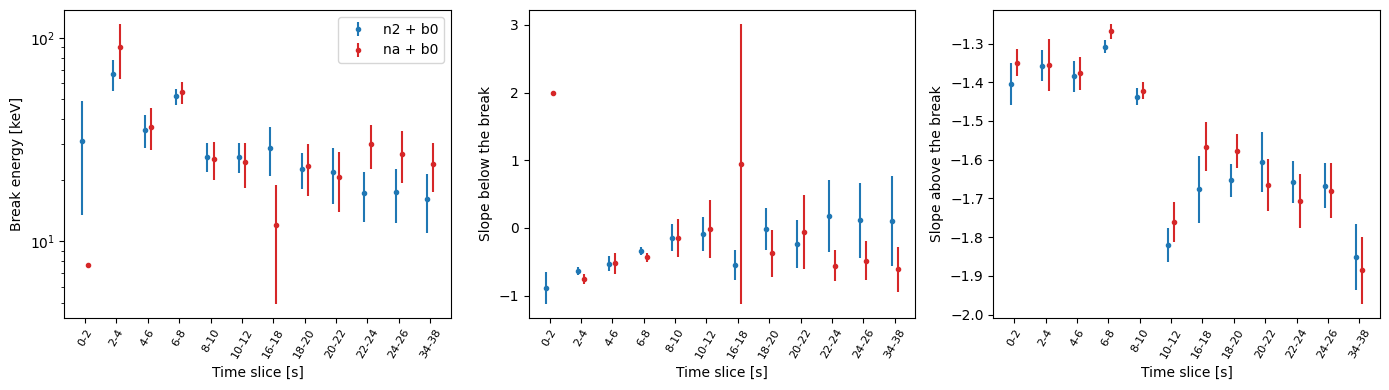

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
x = np.arange(len(TWO_BREAK))
for ax, value, error, name in ((axes[0], "Eb", "Eb_err", "Break energy [keV]"), (axes[1], "alpha1", "alpha1_err", "Slope below the break"), (axes[2], "alpha2", "alpha2_err", "Slope above the break")):
    for offset, det, colour in ((-0.1, "n2", "tab:blue"), (0.1, "na", "tab:red")):
        ax.errorbar(x + offset, wide[value][det], yerr=wide[error][det], fmt="o", ms=3, color=colour, label=f"{det} + b0")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{WIN[l][0]:g}-{WIN[l][1]:g}" for l in TWO_BREAK], rotation=60, fontsize=8)
    ax.set_xlabel("Time slice [s]")
    ax.set_ylabel(name)
axes[0].set_yscale("log")
axes[0].legend()
fig.tight_layout()
fig.savefig(S.FIGURE_DIR / "16_n2_na_break.png", dpi=200)
plt.show()

Both detectors do see the low energies here. n2 is 30 deg from the burst with 96.5 cm2 at 25 keV, and na is 49.5 deg with 67 cm2. Summed over the slices they have about 86600 and 55900 net counts at 8-40 keV, so the test can be done, which isn't the case for GRB 230307A.

The two-break model improves on Band in every slice with both detectors: Delta C is 12-902 with n2 + b0 and 13-520 with na + b0 in its clean fits (8 in `g00_02`, which isn't clean). And they agree on where the break is: in all 11 slices where both fits are clean, E_b differs by at most 1.6 sigma and alpha1 by at most 1.4 sigma. The one exception is `g00_02`, the faint first slice, where na's fit runs into the edge of the fit range and n2 finds 31 +/- 18 keV with Delta C of only 12.

If the break came from a calibration problem in one detector, it would show up in that detector only, or at a different energy, and it doesn't. It could still come from something all the NaI share, but the break moves, from 66 keV at 2-4 s down to 16-18 keV after 22 s in n2. That doesn't look like a fixed feature of the response, such as the iodine K-edge at 33 keV. It's the same range as Gompertz et al.'s (64.3 +/- 4.9 down to 17.6 +/- 4.2 keV). The mean slope above the break is -1.57 with either detector, against their -1.61 +/- 0.25, and -3/2 is what fast-cooling synchrotron predicts. The mean slope below it is -0.25 with n2 and -0.28 with na, against their -0.52 +/- 0.24 and the predicted -2/3, but that's an unweighted mean with a big scatter (0.34 and 0.47), since the later slices have large errors on it. The first slices with small errors are at -0.63 +/- 0.06 and -0.34 +/- 0.06.

So I'd take the break in GRB 211211A as real, which is what Gompertz et al. (2023) find with Swift/BAT and GBM together. It doesn't show the same for GRB 230307A, where only na sees below 40 keV, so that question stays open (README, open point 3). Still, the break there moves as well, from 159 keV at 7-9 s to 16 keV at 22-25.5 s (notebook 12), which doesn't look like a fixed feature either.

## 5. The table

One row per window, kept apart from `shared/epeak_211211A.csv`.

In [9]:
out = pd.DataFrame({"t_start": windows.t_start, "t_stop": windows.t_stop, "model": table.model, "Epeak_keV": table.Epeak_keV,
                    "Epeak_sys": syst.Epeak_sys, "alpha_sys": syst.alpha_sys,
                    "dEpeak_BGO_300keV": syst["dEpeak BGO from 300 keV"], "dEpeak_interpolated_response": syst["dEpeak interpolated response"],
                    "dEpeak_background_order2": syst["dEpeak background order 2"],
                    "b0_max_kcps": rate_table.b0_max_kcps, "n2_max_kcps": rate_table.n2_max_kcps, "na_max_kcps": rate_table.na_max_kcps,
                    "pileup_Epeak_band_ratio_sim": pileup.Epeak_ratio.reindex(windows.index)})
out.to_csv(SHARED / "epeak_211211A_systematics.csv", float_format="%.5g")
print("saved", SHARED / "epeak_211211A_systematics.csv")
out.round(3)

saved /home/ignaciobl2004/mphys_project/ignacio/shared/epeak_211211A_systematics.csv


,t_start,t_stop,model,Epeak_keV,Epeak_sys,alpha_sys,dEpeak_BGO_300keV,dEpeak_interpolated_response,dEpeak_background_order2,b0_max_kcps,n2_max_kcps,na_max_kcps,pileup_Epeak_band_ratio_sim
label,,,,,,,,,,,,,
pre,-0.016,0.432,Comptonized,66.748,1.068,0.036,0.140,0.000,-1.059,3.125,7.688,6.812,NaN
g00_02,0.000,2.000,BandLowBreak,1565.830,55.937,0.172,8.685,2.837,55.186,34.500,37.625,26.625,1.017
g02_04,2.000,4.000,BandLowBreak,1212.140,28.449,0.031,25.566,1.237,12.418,36.125,43.500,31.813,1.002
g04_06,4.000,6.000,BandLowBreak,828.512,22.802,0.034,20.796,4.827,8.011,22.750,32.562,24.750,0.998
g06_08,6.000,8.000,BandLowBreak,1606.910,13.245,0.018,7.852,7.520,7.565,42.437,50.937,40.000,1.007
g08_10,8.000,10.000,BandLowBreak,1257.740,14.994,0.066,2.467,7.454,12.774,24.562,30.937,26.187,1.001
g10_12,10.000,12.000,BandLowBreak,532.934,12.673,0.083,-4.842,10.431,5.325,5.625,12.812,10.500,NaN
g12_16,12.000,16.000,Comptonized,203.350,4.268,0.023,-3.710,1.660,-1.302,3.437,5.625,7.250,NaN
g16_18,16.000,18.000,BandLowBreak,370.705,21.299,0.105,-15.862,7.259,-12.221,6.500,11.938,10.312,NaN
